In [1]:
import pathlib

import navis.interfaces.neuprint as neu
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import plotting
from el_hd_plasticity.connectomics import synapse_distance as sd
from el_hd_plasticity.connectomics.run_epg_instance_distance import get_er_epg_synapses

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'      # written by el_hd_plasticity.connectomics.run_epg_instance_distance
client = cn.npt_client()

## Distance between the synapses of an ER neuron onto EPG neurons of different instances

For every synapse of an ER neuron onto an EPG neuron (a presynaptic site on the ER neuron), the cable distance along the ER neuron to the
nearest synapse onto an EPG of a *different instance* (e.g. `EPG(PB08)_L3` vs `EPG(PB08)_R3`), computed by
`python -m el_hd_plasticity.connectomics.run_epg_instance_distance`. Same limits, scale and bins as the EL distance analyses
(`synapse_distance.ipynb`): paths up to 15 microns, histograms over 0-16 microns.

### Example ER4d axon

In [2]:
ebcoords = cn.EBCoordinateSystem()
eb = ebcoords.fetch_roi('EB')

ers, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='ER4d'))
example_er4d = ers['bodyId'].iloc[3]
er4d_skeleton = ebcoords.fetch_skeleton(example_er4d)

# er3ps, _ = neu.queries.fetch_neurons(neu.NeuronCriteria(type='ER3p.*'))
# example_er3p = er3ps['bodyID'].iloc[0]

syns, _ = get_er_epg_synapses('ER4d')
syns = cn.add_eb_coords(syns.loc[syns['bodyId_pre'] == example_er4d].copy(), ebcoords, type='pre')

# syns_er3p, _ = get_er_epg_synapses('ER3p.*')

# the two instances with most synapses onto the example neuron
instances = syns['type'].value_counts().index[:2]

print(syns['type'].value_counts().head(16).to_dict())

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/connectomics/connectomics.py:250: UserWarning: 
The coefficients of the spline returned have been computed as the
minimal norm least-squares solution of a (numerically) rank deficient
system (deficiency=92). If deficiency is large, the results may be
inaccurate. Deficiency may strongly depend on the value of eps.
  self._xsec_rad_spline = sp.interpolate.LSQBivariateSpline(eb_phase, xsec_phase, xsec_rad, knots, knots)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (20 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

{'EPG(PB08)_L8': 38, 'EPG(PB08)_L1': 31, 'EPG(PB08)_L7': 25, 'EPG(PB08)_R7': 25, 'EPG(PB08)_R4': 24, 'EPG(PB08)_L4': 24, 'EPG(PB08)_R8': 23, 'EPG(PB08)_L3': 23, 'EPG(PB08)_R1': 23, 'EPG(PB08)_L2': 23, 'EPG(PB08)_L6': 22, 'EPG(PB08)_L5': 20, 'EPG(PB08)_R3': 19, 'EPG(PB08)_R2': 18, 'EPG(PB08)_R6': 16, 'EPG(PB08)_R5': 10}


In [3]:
_instances = [instances[0], 'EPG(PB08)_R1']

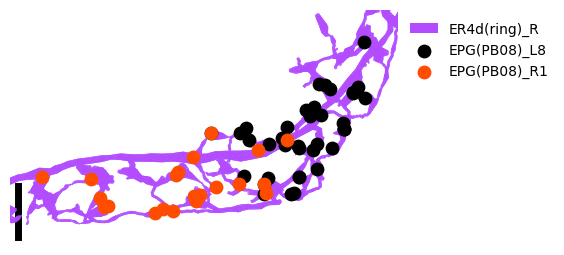

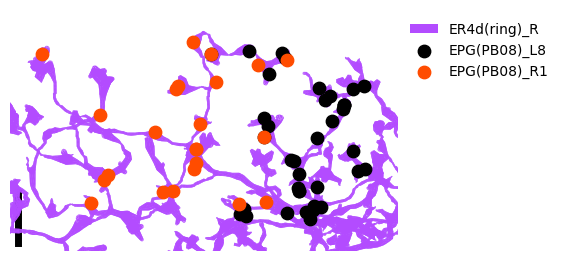

In [4]:
colors = ('black', plt.cm.autumn(.3))
selected = syns[syns['type'].isin(_instances)]
margin = 400                                     # voxels around the synapses shown

for plane in ('xy', 'xz'):
    axes = tuple(plane)
    fig, ax = plotting.plot_neurons_2d([er4d_skeleton], colors=plt.cm.cool(.7), view=axes, linewidth=1.)
    for instance, color in zip(_instances, colors, strict=True):
        syn = selected[selected['type'] == instance]
        ax.scatter(syn[f'{axes[0]}_eb'], syn[f'{axes[1]}_eb'], s=80, color=color, zorder=100, label=instance)
    ax.set_xlim(selected[f'{axes[0]}_eb'].min() - margin, selected[f'{axes[0]}_eb'].max() + margin)
    ax.set_ylim(selected[f'{axes[1]}_eb'].min() - margin, selected[f'{axes[1]}_eb'].max() + margin)
    ax.plot([ax.get_xlim()[0] + 100] * 2, [ax.get_ylim()[0] + 100, ax.get_ylim()[0] + 100 + 1000 / 8 * 5], linewidth=5, color='black')   # 5 micron bar
    ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False)
    fig.savefig(figfolder / f'er4d_epg_instance_synapses_{plane}.png', dpi=500, transparent=True, bbox_inches='tight')

### Example axons of the other ER types

One neuron per type, with the synapses of its most-synapsed instance and the two instances whose synapse centroids are closest to it.

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/14903 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (79 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

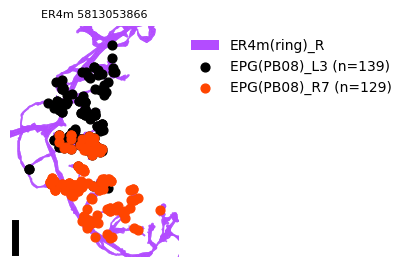

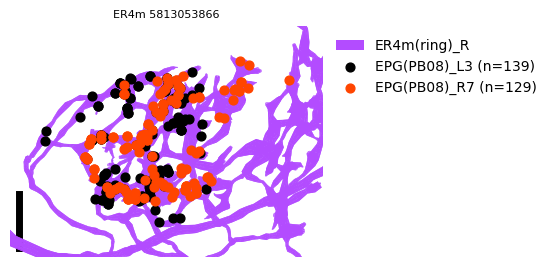

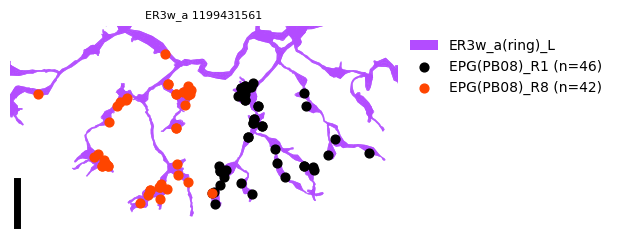

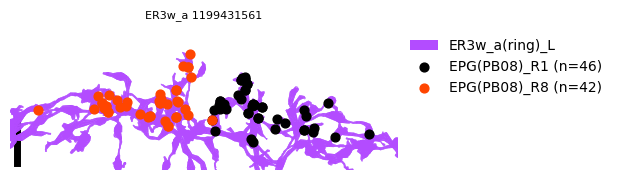

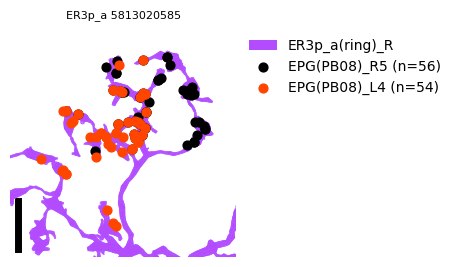

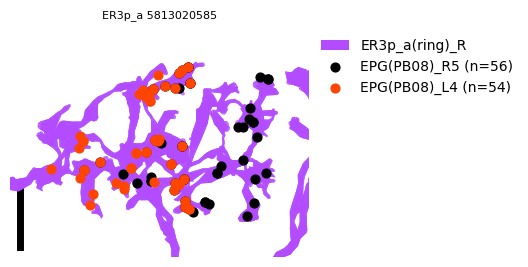

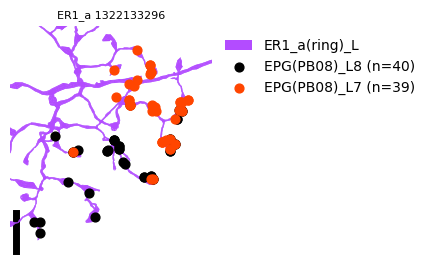

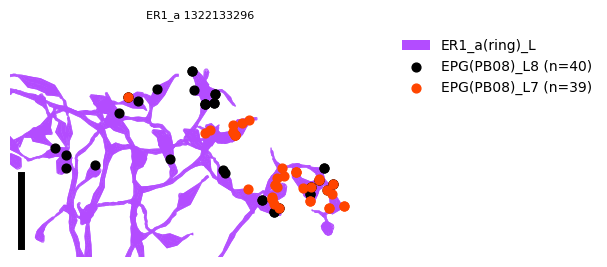

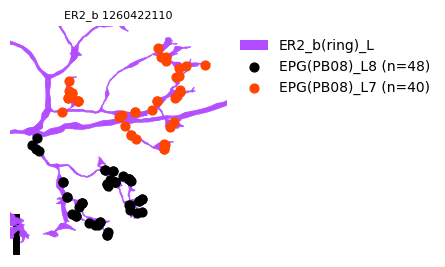

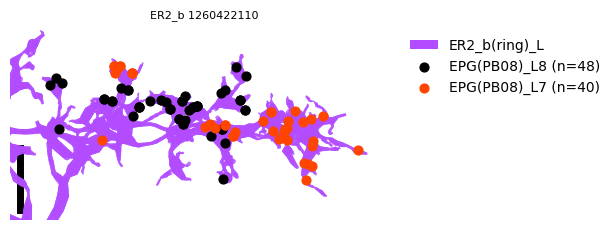

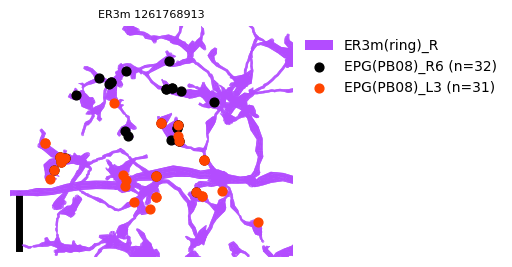

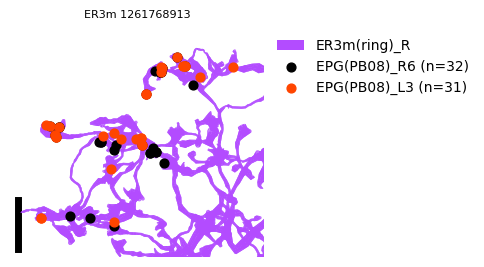

In [5]:
for er_type in ('ER4m', 'ER3w_a', 'ER3p_a', 'ER1_a', 'ER2_b', 'ER3m'):
    er_syns, _ = get_er_epg_synapses(er_type)
    body_id = er_syns['bodyId_pre'].value_counts().index[0]            # the neuron with most synapses
    er_syns = cn.add_eb_coords(er_syns.loc[er_syns['bodyId_pre'] == body_id].copy(), ebcoords, type='pre')
    instances = sd.adjacent_instances(er_syns)
    skeleton = ebcoords.fetch_skeleton(body_id)
    for plane in ('xy', 'xz'):
        fig, ax = plotting.plot_instance_example(skeleton, er_syns, instances, view=tuple(plane))
        ax.set_title(f'{er_type} {body_id}', fontsize=8)
        fig.savefig(figfolder / f'{er_type}_epg_instance_synapses_{plane}.png', dpi=500, transparent=True, bbox_inches='tight')


### Distances

In [6]:
distance_df = sd.load_instance_distance_table(syndist_folder, sd.ER_TYPES)
print(distance_df.groupby('er')['distances'].agg(['size', lambda d: d.notna().mean()]).rename(columns={'<lambda_0>': 'fraction with a partner'}).round(2))

         size  fraction with a partner
er                                    
ER1_a    6111                     1.00
ER1_b    5562                     1.00
ER2_a    5091                     1.00
ER2_b    3073                     1.00
ER2_c   12671                     1.00
ER2_d    3249                     1.00
ER3a_a    314                     1.00
ER3a_b     74                     1.00
ER3a_c    595                     1.00
ER3a_d     46                     1.00
ER3d_a   2864                     1.00
ER3d_b   1916                     1.00
ER3d_c   2494                     1.00
ER3d_d   1639                     1.00
ER3m     3569                     1.00
ER3p_a   7053                     1.00
ER3p_b   2532                     1.00
ER3w_a   4723                     1.00
ER3w_b   5874                     1.00
ER4d    10000                     0.86
ER4m    14903                     1.00


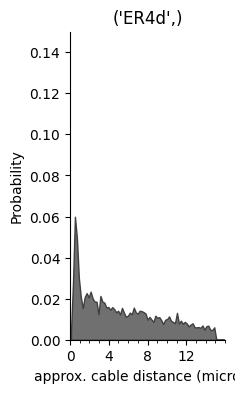

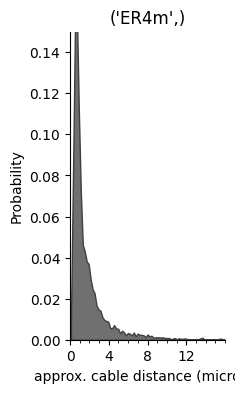

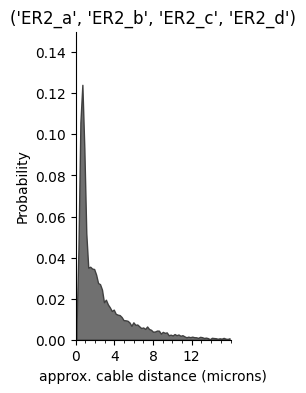

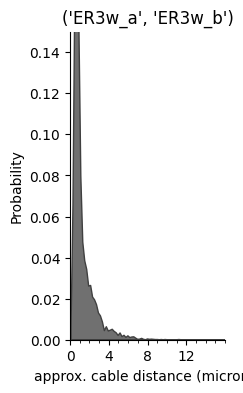

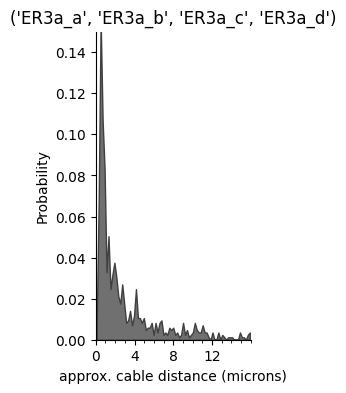

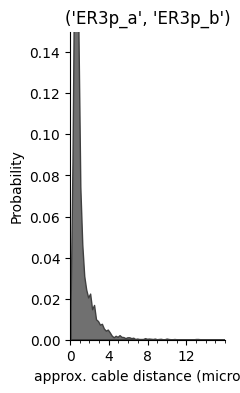

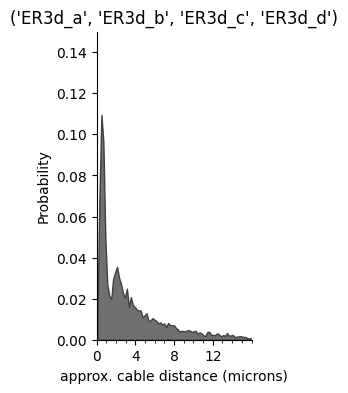

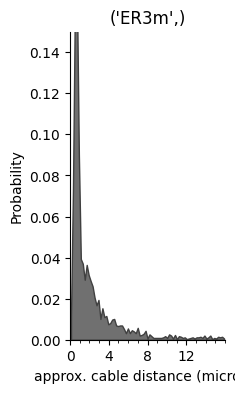

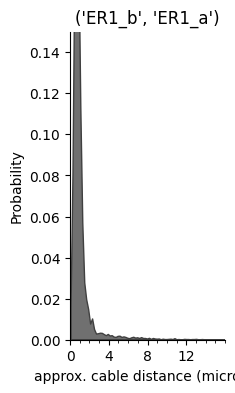

In [7]:
for i, group in enumerate(sd.ER_GROUPS):
    fig, ax = plotting.plot_family_distance_histogram(distance_df, group, source='epg_instance', color=plt.cm.Greys(.8))
    fig.savefig(figfolder / f'group{i}_epg_instance_dist.pdf')

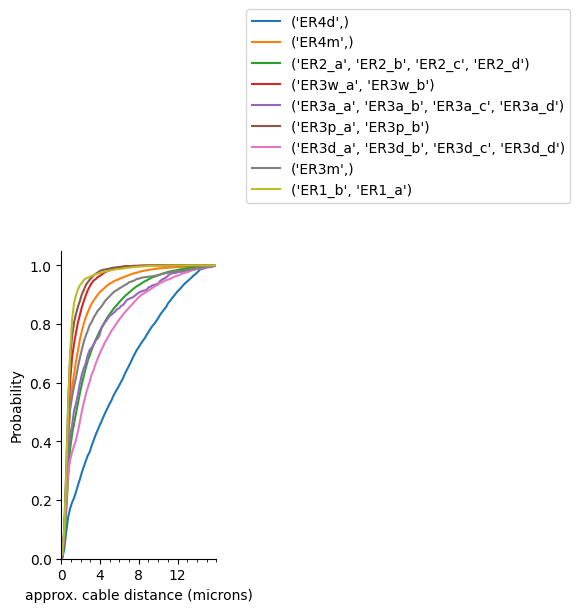

In [8]:
fig, axs = plotting.plot_cumulative_distances(distance_df, sd.ER_GROUPS, sources=('epg_instance',), figsize=(2, 4))
fig.savefig(figfolder / 'all_epg_instance_dist_cumulative.pdf', bbox_inches='tight')